## short-term Memory 

 대화 맥락을 이해하는 에이전트

# 랭그래프에서 단기 메모리 사용하기

In [1]:
from langgraph.checkpoint.memory import InMemorySaver  # 메모리(RAM)에 체크포인트를 저장하는 세이버
from langgraph.graph import StateGraph  # 상태 기반 그래프 빌더
from typing import Annotated  # 타입에 메타데이터(리듀서)를 붙이기 위한 도구

from operator import add  # 두 값을 더하는 함수, 여기서는 리듀서로 사용

# [ 1 ] 상태 스키마를 TypedDict가 아닌 단일 int 값으로 지정
#       Annotated[int, add] -> 상태 타입은 int, 값 갱신 방식(리듀서)은 add
#       즉 노드가 반환한 값은 기존 상태를 "덮어쓰지" 않고 기존 상태에 "더해짐"
graph_builder = StateGraph(Annotated[int, add])

# [ 2 ] "get_one" 노드 등록: 입력 x가 무엇이든 항상 1을 반환
#       리듀서가 add이므로 반환값 1은 현재 상태에 누적 합산됨
graph_builder.add_node("get_one", lambda x: 1)

graph_builder.set_entry_point("get_one")   # 그래프 시작 노드 지정
graph_builder.set_finish_point("get_one")  # 그래프 종료 노드 지정 (실행 후 END로 연결)

# [ 3 ] 체크포인터를 붙여 컴파일
#       실행이 끝난 시점의 상태가 thread_id 별로 저장되고, 다음 호출 시 그 상태에서 이어짐
graph = graph_builder.compile(checkpointer=InMemorySaver())


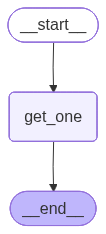

In [2]:
graph 

In [3]:

# [ 4 ] thread_id="user1" 스레드로 그래프 실행
#       입력 0도 리듀서 add를 통해 상태에 더해짐 (초기 상태 0 + 입력 0 = 0)
#       이후 노드가 1을 반환 -> 0 + 1 = 1
result1 = graph.invoke(0, {"configurable": {"thread_id": "user1"}})
print(f"첫 번째 호출 결과: {result1}\n")

# 같은 thread_id 이므로 이전 체크포인트 상태(1)에서 시작
# 1 + 입력 0 = 1, 노드 반환값 1 누적 -> 2
result2 = graph.invoke(0, {"configurable": {"thread_id": "user1"}})
print(f"두 번째 호출 결과: {result2}\n")

# 이전 상태(2)에서 시작 -> 2 + 0 = 2, 노드 반환값 1 누적 -> 3
result3 = graph.invoke(0, {"configurable": {"thread_id": "user1"}})
print(f"세 번째 호출 결과: {result3}")

첫 번째 호출 결과: 1

두 번째 호출 결과: 2

세 번째 호출 결과: 3


# Use in subgraphs

https://docs.langchain.com/oss/python/langgraph/add-memory#use-in-subgraphs

그래프에 서브그래프가 포함된 경우 , 부모 그래프를 컴파일할 때 체크포인터만 제공하면 됩니다. 

LangGraph는 체크포인터를 자식 서브그래프에 자동으로 전달합니다.


In [7]:
# LangGraph의 그래프 시작점(START)과 상태 그래프 클래스를 가져옴
from langgraph.graph import START, StateGraph
# 메모리 기반 체크포인터(short-term memory 저장용)를 가져옴
from langgraph.checkpoint.memory import InMemorySaver
# 상태 스키마 정의에 사용할 TypedDict를 가져옴
from typing import TypedDict

# 그래프의 상태 스키마 정의 (foo라는 문자열 필드 하나를 가짐)
class State(TypedDict):
    foo: str

# Subgraph
# 서브그래프의 노드 함수: 상태의 foo 값 뒤에 "bar"를 붙여 반환함
def subgraph_node_1(state: State):
    return {"foo": state["foo"] + "bar"}

# 서브그래프 빌더 생성 (State 스키마 사용)
subgraph_builder = StateGraph(State)
# 서브그래프에 노드 추가 (함수 이름이 노드 이름으로 사용됨)
subgraph_builder.add_node(subgraph_node_1)
# START에서 subgraph_node_1로 가는 엣지 추가
subgraph_builder.add_edge(START, "subgraph_node_1")
# 서브그래프 컴파일 (체크포인터는 부모 그래프에서 전파되므로 여기서는 지정하지 않음)
subgraph = subgraph_builder.compile()

# Parent graph
# 부모 그래프 빌더 생성 (State 스키마 사용)
builder = StateGraph(State)
# 컴파일된 서브그래프를 부모 그래프의 노드("node_1")로 추가
builder.add_node("node_1", subgraph)
# START에서 node_1로 가는 엣지 추가
builder.add_edge(START, "node_1")
# 메모리 기반 체크포인터 생성 (thread_id 단위로 상태를 저장함)
checkpointer = InMemorySaver()
# 부모 그래프 컴파일 시 체크포인터 지정 (서브그래프에도 자동으로 전파됨)
graph = builder.compile(checkpointer=checkpointer)

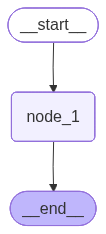

In [5]:
graph 

In [6]:
# ===== 실행 코드 추가 =====

# thread_id를 지정한 config 생성 (체크포인터가 이 ID 기준으로 상태를 저장함)
config = {"configurable": {"thread_id": "1"}}

# 그래프 실행 (부모 그래프의 node_1이 서브그래프를 호출함)
result = graph.invoke({"foo": "hello "}, config)

# 실행 결과 출력
print(result)

# 체크포인터에 저장된 현재 상태(short-term memory) 확인
print(graph.get_state(config))

{'foo': 'hello bar'}
StateSnapshot(values={'foo': 'hello bar'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f17f28c-428a-6101-8001-17c4704c74cb'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-07-14T02:07:29.161241+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f17f28c-427e-6c0e-8000-968c9c1f5d50'}}, tasks=(), interrupts=())


#  [실습] 챗봇에 단기 메모리 적용하기

In [28]:
from typing import Annotated  # 타입에 리듀서 등 메타데이터를 부착하기 위한 도구
from typing_extensions import TypedDict  # 딕셔너리 형태의 상태 스키마 정의용

from langgraph.graph import StateGraph  # 상태 기반 그래프 빌더
from langgraph.graph.message import add_messages  # 메시지 리스트 전용 리듀서
from langgraph.checkpoint.memory import InMemorySaver  # 메모리에 대화 상태를 저장하는 체크포인터
from langgraph.graph import StateGraph
from langchain_openai import ChatOpenAI  # OpenAI 챗 모델 래퍼

from dotenv import load_dotenv

load_dotenv()  # .env 파일에서 OPENAI_API_KEY 등 환경변수를 읽어 등록

# [ 1 ] 그래프 상태 스키마 정의
#       messages 키는 리스트이며, 리듀서로 add_messages를 사용
#       add_messages는 기존 메시지 리스트를 덮어쓰지 않고 뒤에 이어붙임(append)
#       또한 dict 형태의 메시지를 LangChain Message 객체로 변환하고,
#       동일한 id를 가진 메시지가 오면 교체 처리함
class State(TypedDict):
    messages: Annotated[list, add_messages]


llm = ChatOpenAI(model="gpt-5-mini")  # [ 2 ] 사용할 LLM 인스턴스 생성

# 노드 함수: 현재 상태의 전체 메시지 이력을 LLM에 전달하고
# 응답 AIMessage를 messages에 추가하도록 반환
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

graph_builder = StateGraph(State)  # [ 3 ] State 스키마로 그래프 빌더 생성
graph_builder.add_node("chatbot", chatbot)  # chatbot 노드 등록
graph_builder.set_entry_point("chatbot")   # 시작 노드 지정
graph_builder.set_finish_point("chatbot")  # 종료 노드 지정

checkpointer = InMemorySaver()  # thread_id 별로 상태를 저장할 체크포인터
graph = graph_builder.compile(checkpointer=checkpointer)  # 체크포인터를 붙여 그래프 컴파일




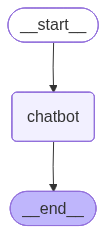

In [29]:
graph

In [30]:
# thread_id "1" 스레드에서 첫 번째 대화 실행
# 입력 메시지가 add_messages 리듀서로 상태에 추가되고,
# chatbot 노드가 LLM 응답을 다시 상태에 추가함
# 실행 종료 시점의 상태(사용자 메시지 + AI 응답)가 체크포인트로 저장됨
graph.invoke(
    {"messages": [{"role": "user", "content": "안녕하세요! 제 이름은 김진오입니다."}]},
    {"configurable": {"thread_id": "1"}},
)

{'messages': [HumanMessage(content='안녕하세요! 제 이름은 김진오입니다.', additional_kwargs={}, response_metadata={}, id='eb6f7b0f-d092-4cd6-9b4e-976b141e1bca'),
  AIMessage(content='안녕하세요 김진오님! 만나서 반갑습니다. 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 94, 'prompt_tokens': 17, 'total_tokens': 111, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-E14kMaxxUCOnvvDcXrTmWSq3e1urR', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f5a3b-90c9-7cd2-bd39-8342ac40bd72-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 17, 'output_tokens': 94, 'total_tokens': 111, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_toke

In [31]:
# 동일한 thread_id "1"로 실행
# 저장된 체크포인트(이전 대화 이력)를 불러온 뒤 새 사용자 메시지를 뒤에 이어붙임
# 따라서 LLM은 이전 대화까지 함께 보게 되어 이름을 기억한 것처럼 답변함
graph.invoke(
    {"messages": [{"role": "user", "content": "제 이름이 뭐라고요?"}]},
    {"configurable": {"thread_id": "1"}},
)

{'messages': [HumanMessage(content='안녕하세요! 제 이름은 김진오입니다.', additional_kwargs={}, response_metadata={}, id='eb6f7b0f-d092-4cd6-9b4e-976b141e1bca'),
  AIMessage(content='안녕하세요 김진오님! 만나서 반갑습니다. 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 94, 'prompt_tokens': 17, 'total_tokens': 111, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-E14kMaxxUCOnvvDcXrTmWSq3e1urR', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f5a3b-90c9-7cd2-bd39-8342ac40bd72-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 17, 'output_tokens': 94, 'total_tokens': 111, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_toke

#  단기 메모리를 관리하는 방법




#  [실습] Trim messages

https://docs.langchain.com/oss/python/langgraph/add-memory#trim-messages


대부분의 LLM(Language Logistics Manager)은 지원하는 최대 컨텍스트 윈도우(토큰 수로 표시됨)를 가지고 있습니다. 

메시지를 잘라낼 시점을 결정하는 한 가지 방법은 메시지 기록의 토큰 수를 세어 해당 제한에 가까워지면 잘라내는 것입니다. 

LangChain을 사용하는 경우, `trim messages` 유틸리티를 사용하여 목록에서 유지할 토큰 수와 경계를 처리하는 데 사용할 기준 

strategy(예: 마지막 토큰 유지 )을 지정할 수 있습니다.max_tokens

In [32]:
from dotenv import load_dotenv

load_dotenv()

True

In [33]:
from langchain_core.messages.utils import (
    trim_messages,              # 메시지 이력을 토큰 한도에 맞게 잘라내는 유틸
    count_tokens_approximately  # 토큰 수를 근사 계산하는 함수 (정확한 토크나이저 대신 빠른 추정)
)
from langchain.chat_models import init_chat_model  # 문자열 식별자로 챗 모델을 초기화
from langgraph.graph import StateGraph, START, MessagesState
# MessagesState: messages: Annotated[list, add_messages] 를 미리 정의해 둔 내장 상태 스키마
from langgraph.checkpoint.memory import InMemorySaver

model = init_chat_model("openai:gpt-5-mini")  # "제공자:모델명" 형식으로 모델 생성

def call_model(state: MessagesState):
    # [ 1 ] 상태에 누적된 전체 메시지 이력을 잘라내어 LLM 입력으로 사용
    messages = trim_messages(
        state["messages"],
        strategy="last",                        # 최근 메시지부터 남김 (뒤에서부터 채움)
        token_counter=count_tokens_approximately,  # 토큰 수 계산에 사용할 함수
        max_tokens=128,                         # 남길 최대 토큰 수 (1024로 늘리면 더 많은 이력 유지)
        start_on="human",                       # 잘라낸 결과가 human 메시지로 시작하도록 보정
        end_on=("human", "tool"),               # 잘라낸 결과가 human 또는 tool 메시지로 끝나도록 보정
    )
    print(f"Trimmed messages: {messages}")      # 실제로 모델에 전달되는 메시지 확인용 출력
    response = model.invoke(messages)           # 잘라낸 메시지만 모델에 전달
    return {"messages": [response]}             # 응답을 상태에 추가 (add_messages 리듀서로 append)


graph_builder = StateGraph(MessagesState)  # [ 2 ] 내장 MessagesState 스키마로 그래프 생성
graph_builder.add_node(call_model)         # 함수명을 그대로 노드 이름("call_model")으로 사용
graph_builder.add_edge(START, "call_model")  # 시작점에서 call_model 노드로 연결

checkpointer = InMemorySaver()  # [ 3 ] thread_id 별 대화 상태를 메모리에 저장
graph = graph_builder.compile(checkpointer=checkpointer)



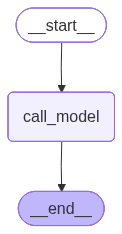

In [34]:
graph 

In [35]:
config = {"configurable": {"thread_id": "1"}}  # 동일 스레드에서 대화 이력을 이어감

graph.invoke({"messages": "안녕, 내 이름은 밥이야"}, config)              # 이름 소개
graph.invoke({"messages": "고양이에 대한 짧은 시를 써줘"}, config)        # 고양이 시 요청
graph.invoke({"messages": "이제 강아지로 똑같이 해줘"}, config)           # 강아지 시 요청
final_response = graph.invoke({"messages": "내 이름이 뭐라고?"}, config)  # 이름 되묻기

final_response["messages"][-1].pretty_print()  # 마지막 AI 응답을 보기 좋게 출력

Trimmed messages: [HumanMessage(content='안녕, 내 이름은 밥이야', additional_kwargs={}, response_metadata={}, id='330ab2e6-f5c5-48c9-8307-cb7e93e5c5eb')]
Trimmed messages: [HumanMessage(content='안녕, 내 이름은 밥이야', additional_kwargs={}, response_metadata={}, id='330ab2e6-f5c5-48c9-8307-cb7e93e5c5eb'), AIMessage(content='안녕 밥! 만나서 반가워. 나는 AI 어시스턴트야. 뭐 도와줄까?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 227, 'prompt_tokens': 16, 'total_tokens': 243, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-E14mFQuZV9dNiIHBdkZBQLlGHuALo', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f5a3d-603e-7e92-a55a-36a395f4f5d8-0', tool_calls=[], invalid_tool_calls=[],

In [36]:
final_response["messages"][-1].pretty_print()  # 마지막 AI 응답을 보기 좋게 출력

================================== Ai Message ==================================

네 이름은 밥이야.


#  [실습] Delete messages

https://docs.langchain.com/oss/python/langgraph/add-memory#delete-messages

메시지 기록을 관리하기 위해 그래프 상태에서 메시지를 삭제할 수 있습니다. 

특정 메시지를 제거하거나 전체 메시지 기록을 지우려는 경우에 유용합니다.

그래프 상태에서 메시지를 삭제하려면 를 사용할 수 있습니다 RemoveMessage. 

이 기능이 제대로 작동하려면 리듀서RemoveMessage 와 함께 상태 키를 사용해야 합니다 (예: ).add_messages MessagesState

In [14]:
from langchain.messages import RemoveMessage

def delete_messages(state):
    messages = state["messages"]
    if len(messages) > 2:
        return {"messages": [RemoveMessage(id=m.id) for m in messages[:2]]}

In [15]:
from langgraph.graph.message import REMOVE_ALL_MESSAGES

def delete_messages(state):
    return {"messages": [RemoveMessage(id=REMOVE_ALL_MESSAGES)]}

---

In [49]:
from dotenv import load_dotenv

load_dotenv()

True

In [50]:
from langchain.messages import RemoveMessage  # 상태에 누적된 메시지를 id로 지목해 삭제하도록 지시하는 특수 메시지

from langchain.chat_models import init_chat_model  # 원본 코드에 누락된 import 보충
from langgraph.graph import StateGraph, START, MessagesState
# MessagesState: messages: Annotated[list, add_messages] 를 미리 정의해 둔 내장 상태 스키마
from langgraph.checkpoint.memory import InMemorySaver


model = init_chat_model("openai:gpt-5-mini")  # "제공자:모델명" 형식으로 모델 생성

def delete_messages(state):
    messages = state["messages"]              # 현재 상태에 쌓여 있는 전체 메시지 리스트
    if len(messages) > 2:                     # 메시지가 2개를 초과할 때만 삭제 수행
        # 가장 오래된 앞쪽 2개 메시지를 삭제 대상으로 지정
        # add_messages 리듀서가 RemoveMessage(id=...)를 받으면 해당 id의 메시지를 상태에서 제거함
        return {"messages": [RemoveMessage(id=m.id) for m in messages[:2]]}
    # 조건이 거짓이면 명시적 return이 없으므로 None 반환 -> 상태 갱신 없음

def call_model(state: MessagesState):
    response = model.invoke(state["messages"])  # 현재 남아 있는 메시지 이력 전체를 모델에 전달
    return {"messages": response}               # 응답을 상태에 추가 (add_messages가 append 처리)

builder = StateGraph(MessagesState)
builder.add_sequence([call_model, delete_messages])  # call_model -> delete_messages 순서로 엣지를 자동 연결
builder.add_edge(START, "call_model")               # 시작점을 call_model 노드로 연결

checkpointer = InMemorySaver()                       # thread_id 별 상태를 메모리에 저장
app = builder.compile(checkpointer=checkpointer)



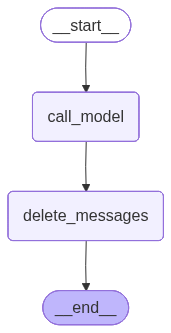

In [51]:
app

In [52]:
# ============================================================
# 첫 번째 대화 실행
# ============================================================

# stream_events(..., version="v3") 호출
#   - v1/v2와 달리 이벤트 dict를 바로 yield 하지 않음
#   - 대신 GraphRunStream 객체를 "즉시" 반환하며, 이 시점에는 그래프가 아직 실행되지 않음
#   - config 에 thread_id 가 들어있으므로 InMemorySaver 체크포인터가 해당 스레드 상태를 불러옴
stream = app.stream_events(
    {"messages": [{"role": "user", "content": "hi! I'm bob"}]},  # 그래프 입력(사용자 메시지)
    config,                                                       # {"configurable": {"thread_id": ...}}
    version="v3"                                                  # v3 스트리밍 프로토콜 사용 (실험적 API)
)

# stream.values : GraphRunStream이 제공하는 "상태 스냅샷" 프로젝션
#   - 노드가 하나 끝날 때마다 그 시점의 "전체 상태(state)"를 하나씩 방출
#   - 이 for 루프가 곧 그래프 실행의 펌프 역할을 함 (백그라운드 스레드 없음)
#     즉, 순회를 시작해야 비로소 call_model -> delete_messages 가 실제로 실행됨
#   - 프로젝션은 단일 소비자 전용이라 같은 stream.values를 두 번 순회할 수 없음
for snapshot in stream.values:
    # snapshot 은 MessagesState 형태의 dict -> snapshot["messages"] 는 메시지 객체 리스트
    # message.type    : "human" / "ai" / "tool" / "system" 등 메시지 종류
    # message.content : 실제 텍스트 내용
    # 스텝이 진행됨에 따라
    #   1) 입력 반영 직후 : [("human", "hi! I'm bob")]
    #   2) call_model 후  : [("human", ...), ("ai", ...)]
    #   3) delete_messages 후 : 메시지가 2개뿐이라 삭제 조건(len > 2) 미충족 -> 그대로 유지
    print([(message.type, message.content) for message in snapshot["messages"]])

print('end===========')  # 첫 번째 실행과 두 번째 실행의 출력 구분용

# ============================================================
# 두 번째 대화 실행 (같은 config -> 같은 thread_id -> 이전 대화 이력 이어받음)
# ============================================================

stream = app.stream_events(
    {"messages": [{"role": "user", "content": "what's my name?"}]},  # 새 사용자 메시지
    config,                                                          # 동일 스레드
    version="v3"
)

for snapshot in stream.values:
    # 이번 실행에서는 체크포인트에 저장된 이전 메시지 2개 + 새 사용자 메시지 = 3개로 시작
    #   1) 입력 반영 직후 : [human(hi! I'm bob), ai(...), human(what's my name?)]  -> 3개
    #   2) call_model 후  : 위 3개 + 새 ai 응답 = 4개
    #      (모델은 아직 삭제 전 이력을 보므로 "bob" 이라고 답할 수 있음)
    #   3) delete_messages 후 : len(messages) > 2 이므로 앞쪽 2개(human/ai)를 RemoveMessage로 제거
    #      -> 최종 상태는 뒤쪽 2개만 남음 [human(what's my name?), ai(...)]
    #      이 잘라낸 상태가 체크포인트에 저장되어 다음 턴으로 넘어감
    print([(message.type, message.content) for message in snapshot["messages"]])

[('human', "hi! I'm bob")]
[('human', "hi! I'm bob"), ('ai', [{'type': 'text', 'text': 'Hi Bob — nice to meet you! How can I help today?', 'index': 0}])]
end===========
[('human', "hi! I'm bob"), ('ai', [{'type': 'text', 'text': 'Hi Bob — nice to meet you! How can I help today?', 'index': 0}]), ('human', "what's my name?")]
[('human', "hi! I'm bob"), ('ai', [{'type': 'text', 'text': 'Hi Bob — nice to meet you! How can I help today?', 'index': 0}]), ('human', "what's my name?"), ('ai', [{'type': 'text', 'text': 'You said your name is Bob.', 'index': 0}])]
[('human', "what's my name?"), ('ai', [{'type': 'text', 'text': 'You said your name is Bob.', 'index': 0}])]


#  Summarize messages

https://docs.langchain.com/oss/python/langgraph/add-memory#summarize-messages

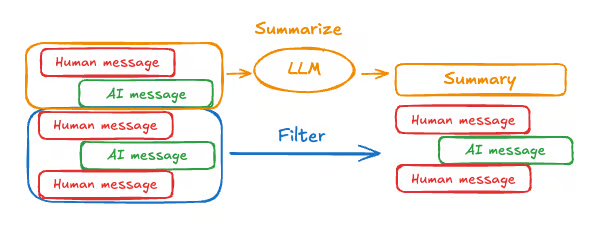

위에서 설명한 것처럼 메시지를 정리하거나 삭제할 때 발생하는 문제는 메시지 큐를 제거하는 과정에서 정보가 손실될 수 있다는 것입니다. 

이러한 이유로 일부 애플리케이션에서는 채팅 모델을 사용하여 메시지 기록을 요약하는 보다 정교한 접근 방식을 사용하는 것이 유리할 수 있습니다.


In [78]:
from langchain_core.messages import HumanMessage, RemoveMessage
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, MessagesState, END
from langgraph.checkpoint.memory import InMemorySaver

# [ 1 ] 그래프 상태: MessagesState(messages)에 summary 문자열 키 추가
#       summary는 리듀서가 없으므로 노드가 반환한 값으로 "덮어쓰기"됨
class State(MessagesState):
    summary: str

model = init_chat_model("openai:gpt-5-mini")  # "제공자:모델명" 형식으로 모델 생성

# [ 2 ] 대화 요약 노드: 누적된 메시지를 요약하고 오래된 메시지를 삭제
def summarize_conversation(state: State):
    summary = state.get("summary", "")  # 기존 요약이 있으면 가져오고 없으면 빈 문자열

    if summary:
        # 기존 요약이 있는 경우: 새 메시지를 반영해 요약을 갱신하도록 지시
        summary_message = (
            f"지금까지 대화 요약: {summary}\n\n"
            "위의 새로운 메시지를 고려하여 요약을 확장해주세요:"
        )
    else:
        # 첫 요약인 경우: 전체 대화를 요약하도록 지시
        summary_message = "위 대화 내용을 요약해주세요:"

    # [ 3 ] 현재 메시지 이력 뒤에 요약 지시 메시지를 붙여 모델에 전달
    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = model.invoke(messages)  # 모델이 생성한 요약 텍스트

    # [ 4 ] 최근 메시지 2개만 남기기
    #       [:-2] -> 마지막 2개를 제외한 앞쪽 메시지 전부를 삭제 대상으로 지정
    #       add_messages 리듀서가 RemoveMessage(id=...)를 받으면 해당 id 메시지를 상태에서 제거
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    # summary 키는 새 요약으로 덮어쓰고, messages 에는 삭제 지시를 전달
    return {"summary": response.content, "messages": delete_messages}

In [79]:
# [ 1 ] LLM 호출 노드: 요약이 있으면 시스템 메시지로 주입한 뒤 모델 호출
def call_model(state: State):
    summary = state.get("summary", "")
    if summary:
        # 삭제된 과거 대화의 내용을 요약 형태로 시스템 메시지에 담아 맥락 유지
        system_message = f"이전 대화 요약: {summary}"
        messages = [{"role": "system", "content": system_message}] + state["messages"]
    else:
        # 요약이 없으면 현재 메시지 이력만 그대로 사용
        messages = state["messages"]

    response = model.invoke(messages)
    return {"messages": [response]}  # 응답을 messages에 추가 (add_messages가 append)

# [ 2 ] 분기 함수: 메시지 개수에 따라 요약 여부 결정
def should_continue(state: State):
    messages = state["messages"]
    if len(messages) > 6:                  # 누적 메시지가 6개를 초과하면
        return "summarize_conversation"    # 요약 노드로 분기
    return "model"                         # 아니면 바로 모델 호출로 분기

# [ 3 ] 그래프 구성
graph_builder = StateGraph(State)
graph_builder.add_node("call_model", call_model)
graph_builder.add_node("summarize_conversation", summarize_conversation)

# 요약 노드 실행 후에는 항상 모델 호출로 이동
graph_builder.add_edge("summarize_conversation", "call_model")
# 시작점에서 should_continue의 반환값에 따라 분기
#   "model" -> call_model 노드로 / "summarize_conversation" -> 요약 노드로
graph_builder.add_conditional_edges(
    START,
    should_continue,
    {
        "model": "call_model",
        "summarize_conversation": "summarize_conversation"
    }
)
graph_builder.add_edge("call_model", END)  # 모델 호출 후 종료

checkpointer = InMemorySaver()  # [ 4 ] thread_id 별 상태(messages + summary)를 메모리에 저장
graph = graph_builder.compile(checkpointer=checkpointer)

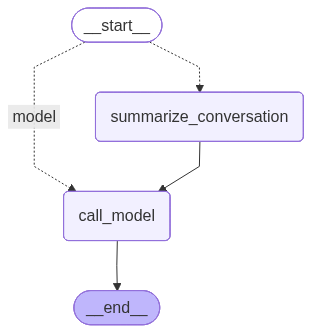

In [80]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [81]:
config = {"configurable": {"thread_id": "1"}}  # 동일 스레드에서 대화 이력 유지

# 턴 1: 메시지 1개 -> 6개 이하 -> 바로 call_model (실행 후 human+ai = 2개)
graph.invoke({"messages": "안녕하세요, 저는 AI를 공부하는 학생입니다."}, config)
# 턴 2: 시작 시 3개(기존 2 + 새 입력 1) -> 6개 이하 -> call_model (실행 후 4개)
graph.invoke({"messages": "앞으로 AI를 사용할 때 주의해야 할 점을 조사하고 있어요."}, config)
# 턴 3: 시작 시 5개 -> 6개 이하 -> call_model (실행 후 6개)
graph.invoke({"messages": "또 어떤 주제에 대해 공부하면 좋을까요?"}, config)
# 턴 4: 시작 시 7개 -> 6개 초과 -> summarize_conversation 실행
#       요약 생성 + 앞쪽 5개 삭제(최근 2개만 유지) -> call_model
#       모델은 "시스템 메시지의 요약 + 최근 2개"를 보고 답변하므로 공부 주제를 기억함
final_response = graph.invoke({"messages": "제가 뭘 공부하고 있나요?"}, config)

# 요약이 생성된 경우에만 출력 (summary 키는 요약 노드가 실행돼야 존재함)
if final_response.get('summary'):
    print(f"요약: {final_response['summary']}\n")
final_response["messages"][-1].pretty_print()  # 마지막 AI 응답 출력

요약: 요약해 드릴게요.

- 당신 정보: AI를 공부하는 학생이라고 소개하셨습니다.
- 초기 질문: 앞으로 AI를 사용할 때 주의할 점을 조사하고 있다고 하셨습니다.
- 보안·윤리·실무 주의사항(조언 내용 요약):
  - 주요 위험: 편향, 개인정보 침해, 안전성(적대적 공격·드리프트), 환각(허위정보), 오용, 과신, 투명성·책임 부족, 법적 리스크, 보안 취약점, 환경비용 등.
  - 권장 대응: 리스크 평가, 데이터 거버넌스, 차등프라이버시·익명화, 공정성 검증, 모델·데이터 문서화(Model Card, Datasheet), 설명가능성 도구(LIME/SHAP), Human-in-the-loop, 적대적·스트레스 테스트, 모니터링·로깅, 접근통제, 출력 필터링, 법적·거버넌스 체계, 지속적 업데이트 등.
  - 간단 체크리스트: 목적·데이터·성능·설명·보안·사용자통제·모니터링·법적검토·사고대응 여부 점검.
  - 참고 프레임워크: NIST AI RMF, OECD 원칙, EU AI Act, Model Cards/Datasheets 등.
- 추가로 공부할 주제(권장 학습 목록):
  - 기초 수학(선형대수·확률·최적화), 머신러닝·딥러닝 기초(역전파, CNN, Transformer), 생성모델(GAN/VAE/Diffusion), 강화학습, 그래프 ML, 시계열·추천·IR, MLOps(데이터 파이프라인·배포·모니터링), 안전성·보안, 프라이버시(차등프라이버시·페더레이티드 러닝), 해석가능성·공정성, 모델경량화(양자화·지식증류), 멀티모달, 논문읽기·재현성, 소프트스킬·법규 등.
  - 각 주제별 추천 교재·강의·도구와 실습/프로젝트 아이디어 제시.
  - 학습 우선순위 제안(초기 3–6개월: 기초+기본 ML·PyTorch, 이후 딥러닝·프로젝트, 그다음 심화 분야 및 MLOps/안전).
- 다음 제안: 현재 수준(수학·프로그래밍)과 목표(연구/취업/도메인)를 알려주면 3/6개월 맞춤 학습계획이나 도메인별 체크리스트·발표자료 등을 만들어 주겠다고 제안드렸습니다.